# Traffic Density and Congestion Estimation from Single Images

**Epoch Zero 2026 · Computer Vision project "Pixels to Measurements"**

From **one road image**, the system measures:

| output | meaning |
|---|---|
| vehicles per class | `car`, `two_wheeler`, `auto_rickshaw`, `bus`, `truck` |
| total vehicles | sum over classes |
| vehicle-type distribution | share of each class (sums to 1) |
| PCU-weighted count | vehicles weighted by passenger-car units (IRC:106-1990) |
| road occupancy | fraction of the road area (ROI) covered by vehicles |
| congestion score / level | score in [0, 1] and **free / moderate / heavy** |

The detector is a COCO-pretrained Ultralytics YOLO **fine-tuned on our data**
(see `notebooks/02_train.ipynb`); this notebook only **loads its saved weights** from `weights/`.
It is compared with two baselines on the **same held-out test set**:
a **classical OpenCV** pipeline (edges + morphology + contours, class-agnostic) and
**Grounding DINO used zero-shot** (text prompts, no training).

**Run it:** *Run All*. Works locally (VS Code, `.venv` kernel) and in Google Colab (mounts Drive).
Set `SMOKE_TEST = True` in the config cell to run the whole pipeline on a tiny public sample
(coco128 vehicles) as a code check. Smoke-test numbers are **not results**.

**Contents:** 1 Setup · 2 Configuration · 3 Data · 4 Models · 5 Predictions · 6 Tuning on validation ·
7 Test evaluation · 8 Results table · 9 Plots · 10 Example outputs · 11 Failure analysis ·
12 External test (Wikimedia Commons photos) · 13 `predict(image_path)`

## 1. Setup

In [1]:
# ------------------------------------------------------------------------------------------
# Environment setup. The same cell works locally (VS Code, .venv kernel) and in Google Colab.
# ------------------------------------------------------------------------------------------
import os, sys, random, subprocess, time, json, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Mount Google Drive and locate the project folder (the one that contains trafficlib.py).
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_FOLDER_NAME = "TrafficProject"   # <- change if your Drive folder has another name
    my_drive = Path("/content/drive/MyDrive")
    candidates = [my_drive / DRIVE_FOLDER_NAME, *my_drive.glob(f"*/{DRIVE_FOLDER_NAME}"),
                  *my_drive.glob(f"*/*/{DRIVE_FOLDER_NAME}")]
    PROJECT_DIR = next((p for p in candidates if (p / "trafficlib.py").exists()), None)
    assert PROJECT_DIR is not None, (
        f"Could not find {DRIVE_FOLDER_NAME}/trafficlib.py in My Drive. If the folder was shared with "
        "you, right-click it > Organize > Add shortcut to My Drive, or edit DRIVE_FOLDER_NAME.")
    # Colab already ships torch, torchvision, transformers, OpenCV, pandas, matplotlib, scikit-learn.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.218", "imagehash"],
                   check=True)
else:
    # Local run: paths are relative to the notebook's own folder (no absolute paths).
    here = Path.cwd()
    PROJECT_DIR = here if (here / "trafficlib.py").exists() else here.parent
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))
print("project folder:", PROJECT_DIR.name, "| running in Colab:", IN_COLAB)

project folder: TrafficProject | running in Colab: False


In [2]:
# Core libraries + fixed seeds (42) so every run gives the same numbers.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import cv2
from IPython.display import display, Markdown
from trafficlib import (CLASS_NAMES, LEVELS, METHOD_HEX, CLASS_HEX, INK_2, MUTED, apply_plot_style, seq_cmap,
                        list_images, load_image_rgb, load_ground_truth, load_rois, get_roi, image_location,
                        measure, boxes_in_roi, yolo_detect, GroundingDINODetector, classical_detect,
                        detection_metrics, count_errors, tune_count_threshold, tune_level_thresholds,
                        congestion_level, draw_detections, box_iou, find_finetuned_weights)
apply_plot_style()

torch 2.14.1+cu126 | device: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Configuration: every constant of the project is in this one cell

**Congestion score.** For an image with per-class counts $n_c$ and road occupancy $o$
(fraction of the road ROI covered by the *union* of vehicle boxes):

$$\text{PCU} = \sum_c w_c\,n_c,\qquad
  \text{score} = \alpha\,\min\!\Big(1,\tfrac{\text{PCU}}{\text{PCU}_{sat}}\Big) + (1-\alpha)\,\min\!\Big(1,\tfrac{o}{o_{sat}}\Big)$$

* $w_c$: passenger-car-unit weights from **IRC:106-1990** *Guidelines for Capacity of Urban Roads in
  Plain Areas*, Table 1 (two-wheeler 0.5, car 1.0, auto-rickshaw 1.2, truck/bus 2.2; "5 % share"
  column). LCVs (1.4) are merged into `truck` and bicycles (0.4) into `two_wheeler`, so those two
  weights are approximations.
* $\text{PCU}_{sat}, o_{sat}$: saturation values, set to the 95th percentile of the ground truth on
  the **validation** set.
* Level thresholds $t_1 < t_2$ (free < $t_1$ ≤ moderate < $t_2$ ≤ heavy) are tuned on the
  **validation** set: against manual labels in `data/val/congestion_labels.csv` if that file exists,
  otherwise at the tertiles of the validation ground-truth score (documented fallback).
* Counting thresholds (detector confidence) and the classical pipeline's parameters are also tuned on
  the validation set only. The test set is used once, for the final numbers.

In [3]:
SMOKE_TEST = False   # True: run everything on data_smoke/ (coco128 vehicles) with SMOKE weights. NOT results.

# ---- paths (relative to the project folder) ----
DATA_DIR     = Path("data_smoke" if SMOKE_TEST else "data")
OUT_DIR      = Path("outputs") / ("smoke" if SMOKE_TEST else "final")
YOLO_WEIGHTS = None            # None = the model chosen and saved by notebooks/02_train.ipynb
ROI_FILE     = DATA_DIR / "rois.json"   # optional road polygons per image / location (default: full frame)

# ---- measurement ----
PCU_WEIGHTS = {"car": 1.0, "two_wheeler": 0.5, "auto_rickshaw": 1.2, "bus": 2.2, "truck": 2.2}  # IRC:106-1990
AGNOSTIC_PCU   = 1.0           # classical baseline has no classes: each blob = 1 car-equivalent
ALPHA          = 0.5           # weight of the PCU term vs the occupancy term
SAT_PERCENTILE = 95            # PCU_SAT / OCC_SAT = this percentile of validation ground truth

# ---- detectors ----
YOLO_IMGSZ      = 960
CONF_GRID       = np.round(np.arange(0.05, 0.851, 0.025), 3)   # candidate counting thresholds
GDINO_MODEL_ID  = "IDEA-Research/grounding-dino-tiny"
GDINO_PROMPTS   = {"car": ["car"], "two_wheeler": ["motorcycle", "scooter", "bicycle"],
                   "auto_rickshaw": ["auto rickshaw"], "bus": ["bus"], "truck": ["truck"]}
GDINO_MIN_SCORE = 0.05         # boxes kept for mAP; the counting threshold is tuned on val
CLASSICAL_BASE  = dict(work_width=960, canny_low=50, canny_high=150, kernel=5, dilate_iter=2,
                       min_area=0.001, max_area=0.15, min_aspect=0.25, max_aspect=4.0, min_fill=0.3)
CLASSICAL_GRID  = {"canny_low": [30, 60], "kernel": [3, 5, 7], "dilate_iter": [1, 2],
                   "min_area": [0.0005, 0.001, 0.002]}           # 36 combinations, tuned on val

# ---- evaluation ----
VAL_TUNE_MAX = 250             # validation images used for tuning (deterministic subset)
WORST_K      = 6               # failure analysis: worst images by count error
N_EXAMPLES   = 3               # example outputs (low / medium / high density)

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "figures").mkdir(exist_ok=True)
(OUT_DIR / "cache").mkdir(exist_ok=True)

def smoke_tag(s=""):
    """Label anything computed in smoke-test mode so it can never be mistaken for a result."""
    return f"[SMOKE TEST - NOT A RESULT] {s}" if SMOKE_TEST else s

def smoke_banner():
    if SMOKE_TEST:
        display(Markdown("> **SMOKE TEST: tiny coco128 sample, numbers below are NOT project results.**"))
print("SMOKE_TEST =", SMOKE_TEST, "| data:", DATA_DIR, "| outputs:", OUT_DIR)

SMOKE_TEST = False | data: data | outputs: outputs\final


## 3. Data
`data/{train,val,test}/{images,labels}` in YOLO format. The split is by **source group**
(pseudo-camera for UVH-26, location for own photos) with seed 42, and was checked for leakage by
perceptual hashing (`notebooks/01_data_prep.ipynb`). File names start with their source:
`uvh26__…` (public UVH-26 CCTV frames) or `own__<location>__…` (own photos).

In [4]:
ROIS = load_rois(ROI_FILE)

def load_split(split):
    """Image paths + ground truth (boxes, classes, size, ROI) for one split."""
    paths = list_images(DATA_DIR / split / "images")
    gts = []
    for p in paths:
        boxes, cls, (h, w) = load_ground_truth(p)
        gts.append({"boxes": boxes, "cls": cls, "h": h, "w": w, "roi": get_roi(p, ROIS)})
    return paths, gts

val_paths_all, val_gt_all = load_split("val")
test_paths, test_gt = load_split("test")

# deterministic validation subset for tuning (bounds the zero-shot model's run time)
rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(val_paths_all), size=min(VAL_TUNE_MAX, len(val_paths_all)), replace=False))
val_paths = [val_paths_all[i] for i in idx]
val_gt = [val_gt_all[i] for i in idx]

def source_of(p):
    return "own photo" if Path(p).name.startswith("own__") else ("UVH-26" if Path(p).name.startswith("uvh26__") else "coco128 (smoke)")

summary = []
for name, paths, gts in [("val (tuning subset)", val_paths, val_gt), ("test", test_paths, test_gt)]:
    cls = np.concatenate([g["cls"] for g in gts]) if gts else np.zeros(0, int)
    src = pd.Series([source_of(p) for p in paths]).value_counts().to_dict()
    summary.append({"split": name, "images": len(paths), "vehicles": len(cls),
                    "vehicles / image": round(len(cls) / max(len(paths), 1), 1),
                    **{c: int((cls == i).sum()) for i, c in enumerate(CLASS_NAMES)}, "sources": src})
display(pd.DataFrame(summary).set_index("split"))
n_own = sum(p.name.startswith("own__") for p in test_paths)
if not SMOKE_TEST and n_own == 0:
    display(Markdown("> The box-annotated test set is held-out UVH-26 cameras (never used in training or "
                     "validation). Photos from a different source are evaluated on congestion level in section 12."))

,images,vehicles,vehicles / image,car,two_wheeler,auto_rickshaw,bus,truck,sources
split,,,,,,,,,
val (tuning subset),250,3122,12.5,735,1487,442,102,356,{'UVH-26': 250}
test,300,4027,13.4,923,1841,637,170,456,{'UVH-26': 300}


> The box-annotated test set is held-out UVH-26 cameras (never used in training or validation). Photos from a different source are evaluated on congestion level in section 12.

## 4. Models
* **Fine-tuned YOLO**: weights loaded from `weights/` (never retrained here).
* **Grounding DINO (zero-shot)**: `IDEA-Research/grounding-dino-tiny` from the Hugging Face hub, prompted with
  one text phrase per class (several phrases for two-wheelers). It is **not** trained on our data.
* **Classical baseline**: no weights; parameters are tuned on the validation set in section 6.

In [5]:
os.environ["YOLO_VERBOSE"] = "False"   # no per-batch progress bars / log lines from Ultralytics
from ultralytics import YOLO

if YOLO_WEIGHTS is None:
    sel = Path("outputs/training") / ("SMOKE_selected_model.json" if SMOKE_TEST else "selected_model.json")
    YOLO_WEIGHTS = Path(json.loads(sel.read_text())["weights"]) if sel.exists() else find_finetuned_weights(".")
assert YOLO_WEIGHTS is not None and Path(YOLO_WEIGHTS).exists(), \
    "No fine-tuned weights found in weights/. Run notebooks/02_train.ipynb first."
yolo = YOLO(str(YOLO_WEIGHTS))
assert list(yolo.names.values()) == CLASS_NAMES, yolo.names
print(f"fine-tuned detector: {Path(YOLO_WEIGHTS).as_posix()} ({Path(YOLO_WEIGHTS).stat().st_size / 1e6:.1f} MB), "
      f"classes {list(yolo.names.values())}")

gdino = GroundingDINODetector(GDINO_MODEL_ID, GDINO_PROMPTS, device=DEVICE)
print("Grounding DINO prompt:", repr(gdino.text))

_stem = Path(YOLO_WEIGHTS).stem.replace("SMOKE_", "").split("_")[0]          # e.g. yolo26s
YOLO_LABEL = f"YOLO{_stem[4:]} fine-tuned" if _stem.lower().startswith("yolo") else f"{_stem} fine-tuned"
def disp(n):
    """Display name of a method (the fine-tuned model is named after its architecture)."""
    return YOLO_LABEL if n == "YOLO fine-tuned" else n

fine-tuned detector: weights/yolo26s_traffic_best.pt (20.3 MB), classes ['car', 'two_wheeler', 'auto_rickshaw', 'bus', 'truck']


Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Grounding DINO prompt: 'car. motorcycle. scooter. bicycle. auto rickshaw. bus. truck.'


## 5. Predictions
Each detector is run once per image and its raw detections are cached in `outputs/…/cache/`
(re-used only if the image list and the detector settings are identical). YOLO keeps boxes down to
confidence 0.001 and Grounding DINO down to 0.05, so mAP sees the full precision-recall curve; the
**counting** threshold is chosen on validation in section 6.

In [6]:
def cached_run(name, paths, fn, signature):
    """Run fn(image_path) -> (boxes, scores, classes) on every image, with a JSON cache."""
    f = OUT_DIR / "cache" / f"{name}.json"
    key = {"files": [p.name for p in paths], "signature": signature}
    if f.exists():
        d = json.loads(f.read_text())
        if d["key"] == key:
            print(f"{name:28s}: cached predictions for {len(paths)} images ({d['sec_per_img']:.3f} s/img when run)")
            return [(np.array(b, np.float32).reshape(-1, 4), np.array(s, np.float32), np.array(c, int))
                    for b, s, c in d["dets"]], d["sec_per_img"]
    dets, t0 = [], time.time()
    for i, p in enumerate(paths):
        dets.append(fn(p))
        if (i + 1) % 100 == 0:
            print(f"  {name}: {i + 1}/{len(paths)}", flush=True)
    sec = (time.time() - t0) / max(len(paths), 1)
    f.write_text(json.dumps({"key": key, "sec_per_img": sec,
                             "dets": [[b.round(2).tolist(), s.round(4).tolist(), c.tolist()] for b, s, c in dets]}))
    print(f"{name:28s}: ran on {len(paths)} images, {sec:.3f} s/img")
    return dets, sec

yolo_sig = {"weights": Path(YOLO_WEIGHTS).name, "bytes": Path(YOLO_WEIGHTS).stat().st_size, "imgsz": YOLO_IMGSZ}
gdino_sig = {"model": GDINO_MODEL_ID, "prompts": GDINO_PROMPTS, "min_score": GDINO_MIN_SCORE}
run_yolo = lambda p: yolo_detect(yolo, load_image_rgb(p), conf=0.001, imgsz=YOLO_IMGSZ, device=DEVICE)
run_gdino = lambda p: gdino.detect(load_image_rgb(p), score_threshold=GDINO_MIN_SCORE)

yolo_val, _ = cached_run("yolo_val", val_paths, run_yolo, yolo_sig)
yolo_test, yolo_sec = cached_run("yolo_test", test_paths, run_yolo, yolo_sig)
gdino_val, _ = cached_run("gdino_val", val_paths, run_gdino, gdino_sig)
gdino_test, gdino_sec = cached_run("gdino_test", test_paths, run_gdino, gdino_sig)

yolo_val                    : cached predictions for 250 images (0.044 s/img when run)
yolo_test                   : cached predictions for 300 images (0.044 s/img when run)


gdino_val                   : cached predictions for 250 images (0.591 s/img when run)


gdino_test                  : cached predictions for 300 images (0.591 s/img when run)


## 6. Tuning on the validation set (never on test)
### 6a. Classical baseline parameters
Grid search over 36 parameter combinations; the one with the lowest validation count MAE wins.

In [7]:
import itertools

def small_copy(p, width=CLASSICAL_BASE["work_width"]):
    """Image resized to the classical pipeline's working width (+ factor back to full resolution)."""
    img = load_image_rgb(p)
    s = width / img.shape[1]
    return cv2.resize(img, (width, max(1, round(img.shape[0] * s))), interpolation=cv2.INTER_AREA), 1 / s

val_small = [small_copy(p) for p in val_paths]
val_gt_total = np.array([boxes_in_roi(g["boxes"], g["w"], g["h"], g["roi"]).sum() for g in val_gt])

grid_rows = []
for values in itertools.product(*CLASSICAL_GRID.values()):
    params = {**CLASSICAL_BASE, **dict(zip(CLASSICAL_GRID.keys(), values))}
    counts = np.array([len(classical_detect(img, params, g["roi"])[0]) for (img, _), g in zip(val_small, val_gt)])
    grid_rows.append({**dict(zip(CLASSICAL_GRID.keys(), values)),
                      "val count MAE": float(np.abs(counts - val_gt_total).mean()),
                      "val count bias": float((counts - val_gt_total).mean())})
grid = pd.DataFrame(grid_rows).sort_values("val count MAE").reset_index(drop=True)
best_row = grid.loc[0]
CLASSICAL_PARAMS = {**CLASSICAL_BASE, **{k: type(CLASSICAL_GRID[k][0])(best_row[k]) for k in CLASSICAL_GRID}}
display(grid.head(5).round(3))
print("selected classical parameters:", CLASSICAL_PARAMS)

def run_classical(p):
    img, back = small_copy(p)
    b, s, c = classical_detect(img, CLASSICAL_PARAMS, get_roi(p, ROIS))
    return b * back, s, c

classical_val, _ = cached_run("classical_val", val_paths, run_classical, CLASSICAL_PARAMS)
classical_test, classical_sec = cached_run("classical_test", test_paths, run_classical, CLASSICAL_PARAMS)
del val_small

,canny_low,kernel,dilate_iter,min_area,val count MAE,val count bias
0,30,3,1,0.000,8.244,-5.060
1,30,3,2,0.000,8.348,-4.380
2,60,3,2,0.001,8.408,-6.192
3,60,3,1,0.000,8.428,-2.684
4,60,5,1,0.000,8.588,-4.204


selected classical parameters: {'work_width': 960, 'canny_low': 30, 'canny_high': 150, 'kernel': 3, 'dilate_iter': 1, 'min_area': 0.0005, 'max_area': 0.15, 'min_aspect': 0.25, 'max_aspect': 4.0, 'min_fill': 0.3}
classical_val               : cached predictions for 250 images (0.024 s/img when run)
classical_test              : cached predictions for 300 images (0.023 s/img when run)


### 6b. Counting thresholds, saturation values and congestion-level thresholds

In [8]:
def gt_measures(gts, cfg, thresholds):
    return [measure(g["boxes"], g["cls"], g["w"], g["h"], cfg, roi=g["roi"], thresholds=thresholds) for g in gts]

def keep_conf(dets, thr):
    return [(b[s >= thr], s[s >= thr], c[s >= thr]) for b, s, c in dets]

# 1) counting thresholds: minimise validation count MAE
YOLO_CONF, yolo_val_mae = tune_count_threshold(yolo_val, val_gt_total, CONF_GRID)
GDINO_CONF, gdino_val_mae = tune_count_threshold(gdino_val, val_gt_total, CONF_GRID)
print(f"counting threshold  YOLO: {YOLO_CONF:.3f} (val MAE {yolo_val_mae:.2f})   "
      f"Grounding DINO: {GDINO_CONF:.3f} (val MAE {gdino_val_mae:.2f})")

# 2) saturation values from validation ground truth
raw_cfg = {"pcu_weights": PCU_WEIGHTS, "agnostic_pcu": AGNOSTIC_PCU, "alpha": ALPHA, "pcu_sat": 1.0, "occ_sat": 1.0,
           "thresholds": (0.33, 0.66)}
val_raw = gt_measures(val_gt, raw_cfg, None)
PCU_SAT = float(np.percentile([m["weighted_count"] for m in val_raw], SAT_PERCENTILE))
OCC_SAT = float(np.percentile([m["occupancy"] for m in val_raw], SAT_PERCENTILE))
CFG = {**raw_cfg, "pcu_sat": round(PCU_SAT, 3), "occ_sat": round(OCC_SAT, 4)}
print(f"PCU_SAT = {CFG['pcu_sat']} PCU, OCC_SAT = {CFG['occ_sat']} (95th percentile of validation ground truth)")

# 3) congestion-level thresholds
def method_measures(dets, gts, conf, agnostic, thresholds):
    out = []
    for (b, s, c), g in zip(keep_conf(dets, conf), gts):
        out.append(measure(b, c, g["w"], g["h"], CFG, roi=g["roi"], class_agnostic=agnostic, thresholds=thresholds))
    return out

val_scores = {
    "gt": [m["congestion_score"] for m in gt_measures(val_gt, CFG, (0.33, 0.66))],
    "yolo": [m["congestion_score"] for m in method_measures(yolo_val, val_gt, YOLO_CONF, False, (0.33, 0.66))],
    "gdino": [m["congestion_score"] for m in method_measures(gdino_val, val_gt, GDINO_CONF, False, (0.33, 0.66))],
    "classical": [m["congestion_score"] for m in method_measures(classical_val, val_gt, 0.0, True, (0.33, 0.66))],
}
val_label_file = DATA_DIR / "val" / "congestion_labels.csv"
if val_label_file.exists():
    lab = pd.read_csv(val_label_file).set_index("image")["level"].to_dict()
    has = [i for i, p in enumerate(val_paths) if p.name in lab]
    y = [lab[val_paths[i].name] for i in has]
    THRESHOLDS = {k: tune_level_thresholds([v[i] for i in has], y)[0] for k, v in val_scores.items()}
    THRESHOLD_SOURCE = f"tuned on {len(has)} manually labelled validation images"
else:
    t = tuple(float(np.round(x, 4)) for x in np.percentile(val_scores["gt"], [100 / 3, 200 / 3]))
    THRESHOLDS = {k: t for k in val_scores}
    THRESHOLD_SOURCE = "tertiles of the validation ground-truth score (no manual validation labels)"
CFG["thresholds"] = THRESHOLDS["yolo"]
print("level thresholds (t1, t2):", {k: tuple(round(x, 3) for x in v) for k, v in THRESHOLDS.items()})
print("source:", THRESHOLD_SOURCE)

TUNED = {"smoke_test": SMOKE_TEST, "yolo_weights": Path(YOLO_WEIGHTS).as_posix(), "yolo_imgsz": YOLO_IMGSZ,
         "yolo_conf": YOLO_CONF, "gdino_model": GDINO_MODEL_ID, "gdino_prompts": GDINO_PROMPTS, "gdino_conf": GDINO_CONF,
         "classical_params": CLASSICAL_PARAMS, "pcu_weights": PCU_WEIGHTS, "agnostic_pcu": AGNOSTIC_PCU,
         "alpha": ALPHA, "pcu_sat": CFG["pcu_sat"], "occ_sat": CFG["occ_sat"],
         "thresholds": {k: list(v) for k, v in THRESHOLDS.items()}, "threshold_source": THRESHOLD_SOURCE,
         "n_val_images_used": len(val_paths)}
(OUT_DIR / "tuned_config.json").write_text(json.dumps(TUNED, indent=2))
print("saved", (OUT_DIR / "tuned_config.json").as_posix())

counting threshold  YOLO: 0.275 (val MAE 1.50)   Grounding DINO: 0.325 (val MAE 2.64)
PCU_SAT = 24.685 PCU, OCC_SAT = 0.5343 (95th percentile of validation ground truth)


level thresholds (t1, t2): {'gt': (0.306, 0.51), 'yolo': (0.306, 0.51), 'gdino': (0.306, 0.51), 'classical': (0.306, 0.51)}
source: tertiles of the validation ground-truth score (no manual validation labels)
saved outputs/final/tuned_config.json


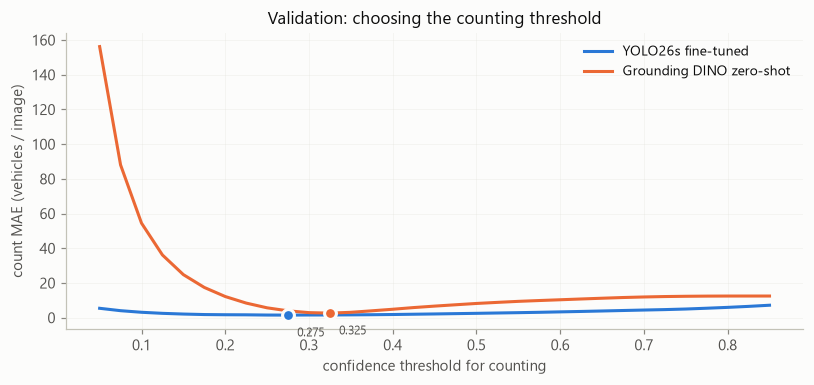

In [9]:
# Validation count error as a function of the counting threshold
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for key, dets, chosen in [("YOLO fine-tuned", yolo_val, YOLO_CONF), ("Grounding DINO zero-shot", gdino_val, GDINO_CONF)]:
    maes = [np.abs(np.array([(s >= t).sum() for _, s, _ in dets]) - val_gt_total).mean() for t in CONF_GRID]
    ax.plot(CONF_GRID, maes, color=METHOD_HEX[key], label=disp(key))
    ax.scatter([chosen], [min(maes)], s=60, color=METHOD_HEX[key], edgecolor="#fcfcfb", linewidth=2, zorder=3)
    ax.annotate(f"{chosen:.3f}", (chosen, min(maes)), textcoords="offset points", xytext=(6, -14), fontsize=8, color=INK_2)
ax.set(xlabel="confidence threshold for counting", ylabel="count MAE (vehicles / image)",
       title=smoke_tag("Validation: choosing the counting threshold"))
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "val_threshold_tuning.png", bbox_inches="tight")
plt.show()

## 7. Evaluation on the held-out test set
For every method: detection quality (mAP, precision, recall), counting error **in vehicles**,
per-class count error, error of the vehicle-type distribution, and congestion-level agreement.
Precision and recall are measured at each method's validation-tuned counting threshold.

In [10]:
METHODS = {  # display name -> (raw test detections, counting threshold, class-agnostic?, sec/img, threshold key)
    "Classical OpenCV": (classical_test, 0.0, True, classical_sec, "classical"),
    "Grounding DINO zero-shot": (gdino_test, GDINO_CONF, False, gdino_sec, "gdino"),
    "YOLO fine-tuned": (yolo_test, YOLO_CONF, False, yolo_sec, "yolo"),
}

def in_roi(b, s, c, g):
    k = boxes_in_roi(b, g["w"], g["h"], g["roi"])
    return b[k], s[k], c[k]

test_gt_roi = [in_roi(g["boxes"], np.ones(len(g["boxes"])), g["cls"], g) for g in test_gt]
gt_eval = [(b, c) for b, _, c in test_gt_roi]
gt_meas = gt_measures(test_gt, CFG, THRESHOLDS["gt"])
gt_counts = [m["counts"] for m in gt_meas]

test_label_file = DATA_DIR / "test" / "congestion_labels.csv"
manual = pd.read_csv(test_label_file).set_index("image")["level"].to_dict() if test_label_file.exists() else {}

R, PER_IMAGE = {}, {}
for name, (dets, conf, agn, sec, tkey) in METHODS.items():
    preds_roi = [in_roi(b, s, c, g) for (b, s, c), g in zip(dets, test_gt)]
    meas = [measure(b, c, g["w"], g["h"], CFG, roi=g["roi"], class_agnostic=agn, thresholds=THRESHOLDS[tkey])
            for (b, s, c), g in zip(keep_conf(preds_roi, conf), test_gt)]
    det_ag = detection_metrics(preds_roi, gt_eval, len(CLASS_NAMES), class_agnostic=True, operating_conf=conf)
    det_cl = None if agn else detection_metrics(preds_roi, gt_eval, len(CLASS_NAMES), operating_conf=conf)
    if agn:
        cnt = count_errors([m["counts"] for m in meas], [{"vehicle": sum(g.values())} for g in gt_counts])
    else:
        cnt = count_errors([m["counts"] for m in meas], gt_counts, CLASS_NAMES)
    lv_pred = [m["congestion_level"] for m in meas]
    lv_gt = [m["congestion_level"] for m in gt_meas]
    man_idx = [i for i, p in enumerate(test_paths) if p.name in manual]
    R[name] = {
        "det_classes": det_cl, "det_agnostic": det_ag, "count": cnt,
        "score_MAE": float(np.mean([abs(a["congestion_score"] - b["congestion_score"]) for a, b in zip(meas, gt_meas)])),
        "level_agree_gt": float(np.mean([a == b for a, b in zip(lv_pred, lv_gt)])),
        "manual_n": len(man_idx),
        "manual_acc": float(np.mean([lv_pred[i] == manual[test_paths[i].name] for i in man_idx])) if man_idx else None,
        "sec_per_img": sec,
    }
    if man_idx:
        from sklearn.metrics import f1_score
        R[name]["manual_f1"] = float(f1_score([manual[test_paths[i].name] for i in man_idx], [lv_pred[i] for i in man_idx],
                                              labels=LEVELS, average="macro", zero_division=0))
    PER_IMAGE[name] = {"meas": meas, "preds_roi": preds_roi, "levels": lv_pred}
print("evaluated", len(test_paths), "test images;", f"manual congestion labels for {len(manual)} of them"
      if manual else "congestion level compared with the level computed from the ground-truth boxes")

evaluated 300 test images; congestion level compared with the level computed from the ground-truth boxes


## 8. Results table (held-out test set)
One row per metric, one column per method. *Class-agnostic* rows treat every vehicle as one class
"vehicle"; they are the only detection rows where the classical baseline can be scored.

In [11]:
smoke_banner()
def f(x, nd=3):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else (f"{x:.{nd}f}" if isinstance(x, float) else str(x))

rows = {}
for name, r in R.items():
    col = {}
    dc, da, c = r["det_classes"], r["det_agnostic"], r["count"]
    col["mAP@0.5 (5 classes)"] = f(dc["mAP50"]) if dc else "n/a"
    col["mAP@0.5:0.95 (5 classes)"] = f(dc["mAP50_95"]) if dc else "n/a"
    col["mAP@0.5 (class-agnostic)"] = f(da["mAP50"])
    col["mAP@0.5:0.95 (class-agnostic)"] = f(da["mAP50_95"])
    col["Precision (vehicle, IoU 0.5)"] = f(da["precision"])
    col["Recall (vehicle, IoU 0.5)"] = f(da["recall"])
    col["Count MAE (vehicles / image)"] = f(c["count_MAE"], 2)
    col["Count bias (vehicles / image)"] = f(c["count_bias"], 2)
    col["Count RMSE (vehicles / image)"] = f(c["count_RMSE"], 2)
    col["Mean % count error per image"] = f(c["mean_pct_error"], 1) + " %"
    for cname in CLASS_NAMES:
        col[f"MAE {cname} (vehicles / image)"] = f(c["per_class_MAE"][cname], 2) if c["per_class_MAE"] else "n/a"
    col["Type-distribution L1 error (0-2)"] = f(c["distribution_L1"]) if c["distribution_L1"] is not None else "n/a"
    col["Congestion score MAE vs GT boxes (0-1)"] = f(r["score_MAE"])
    col["Level agreement with GT-box level"] = f(r["level_agree_gt"])
    if r["manual_acc"] is not None:      # only when manual labels exist for the test images
        col["Level accuracy vs manual labels"] = f(r["manual_acc"]) + f" (n={r['manual_n']})"
        col["Level macro-F1 vs manual labels"] = f(r.get("manual_f1"))
    col["Seconds / image (this machine)"] = f(r["sec_per_img"], 3)
    rows[disp(name)] = col
results = pd.DataFrame(rows)
results.index.name = smoke_tag(f"test set: {len(test_paths)} images, {int(sum(len(b) for b, _ in gt_eval))} vehicles")
display(results)
results.to_csv(OUT_DIR / "results_table.csv")
(OUT_DIR / "results_table.md").write_text(results.to_markdown())

lines = [f"- **{disp(n)}** is off by **{r['count']['count_MAE']:.1f} vehicles per image** on "
         f"average ({r['count']['mean_pct_error']:.0f} % of the true count; bias {r['count']['count_bias']:+.1f})"
         for n, r in R.items()]
display(Markdown(smoke_tag("**Error in real units (test set):**") + "\n" + "\n".join(lines)))

json.dump({"smoke_test": SMOKE_TEST, "n_test_images": len(test_paths), "n_test_vehicles": int(sum(len(b) for b, _ in gt_eval)),
           "n_own_test_images": n_own, "tuned": TUNED, "results": {disp(n): r for n, r in R.items()}},
          open(OUT_DIR / "metrics.json", "w"), indent=2, default=float)

,Classical OpenCV,Grounding DINO zero-shot,YOLO26s fine-tuned
"test set: 300 images, 4027 vehicles",,,
mAP@0.5 (5 classes),n/a,0.519,0.825
mAP@0.5:0.95 (5 classes),n/a,0.349,0.690
mAP@0.5 (class-agnostic),0.003,0.726,0.890
mAP@0.5:0.95 (class-agnostic),0.002,0.394,0.729
"Precision (vehicle, IoU 0.5)",0.040,0.735,0.858
"Recall (vehicle, IoU 0.5)",0.022,0.666,0.832
Count MAE (vehicles / image),8.25,3.21,1.81
Count bias (vehicles / image),-5.90,-1.25,-0.41
Count RMSE (vehicles / image),11.15,4.56,2.52


**Error in real units (test set):**
- **Classical OpenCV** is off by **8.2 vehicles per image** on average (72 % of the true count; bias -5.9)
- **Grounding DINO zero-shot** is off by **3.2 vehicles per image** on average (28 % of the true count; bias -1.3)
- **YOLO26s fine-tuned** is off by **1.8 vehicles per image** on average (19 % of the true count; bias -0.4)

**Cross-check with Ultralytics' own evaluator.** The fine-tuned model's test mAP is recomputed with
`model.val(split="test")`. Small differences are expected: Ultralytics integrates the
precision-recall curve with a trapezoid that caps a perfect AP at 0.995, while the table above uses
the COCO 101-point rule (as in pycocotools).

In [12]:
import yaml
eval_yaml = Path("runs") / f"{'SMOKE_' if SMOKE_TEST else ''}eval_test_data.yaml"
eval_yaml.parent.mkdir(parents=True, exist_ok=True)
eval_yaml.write_text(yaml.safe_dump({"path": str(DATA_DIR.resolve()), "train": "train/images", "val": "val/images",
                                     "test": "test/images", "names": dict(enumerate(CLASS_NAMES))}))
uv = yolo.val(data=str(eval_yaml), split="test", imgsz=YOLO_IMGSZ, batch=4, conf=0.001, iou=0.7,
              device=0 if DEVICE == "cuda" else "cpu", plots=False, verbose=False)
mine = R["YOLO fine-tuned"]["det_classes"]
display(pd.DataFrame({"this notebook (COCO 101-pt)": [mine["mAP50"], mine["mAP50_95"]],
                      "Ultralytics val()": [float(uv.box.map50), float(uv.box.map)]},
                     index=["mAP@0.5", "mAP@0.5:0.95"]).round(4))

,this notebook (COCO 101-pt),Ultralytics val()
mAP@0.5,0.8245,0.8820
mAP@0.5:0.95,0.6903,0.7379


## 9. Plots

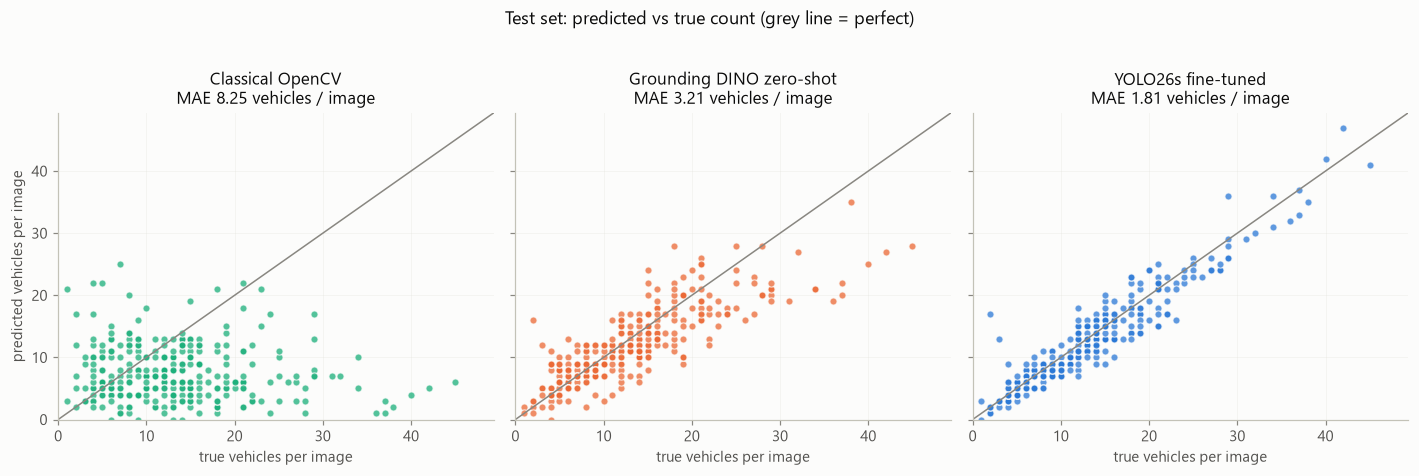

In [13]:
smoke_banner()
gt_tot = np.array([sum(c.values()) for c in gt_counts])
names = list(R)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
lim = max(gt_tot.max(initial=1), max(np.max([m["total"] for m in PER_IMAGE[n]["meas"]], initial=1) for n in names)) * 1.05
for ax, n in zip(axes, names):
    pred = np.array([m["total"] for m in PER_IMAGE[n]["meas"]])
    ax.plot([0, lim], [0, lim], color=MUTED, lw=1)
    ax.scatter(gt_tot, pred, s=22, color=METHOD_HEX[n], alpha=0.75, edgecolor="#fcfcfb", linewidth=0.8)
    ax.set_title(f"{disp(n)}\nMAE {R[n]['count']['count_MAE']:.2f} vehicles / image")
    ax.set_xlabel("true vehicles per image")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
axes[0].set_ylabel("predicted vehicles per image")
fig.suptitle(smoke_tag("Test set: predicted vs true count (grey line = perfect)"), y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "count_scatter.png", bbox_inches="tight")
plt.show()

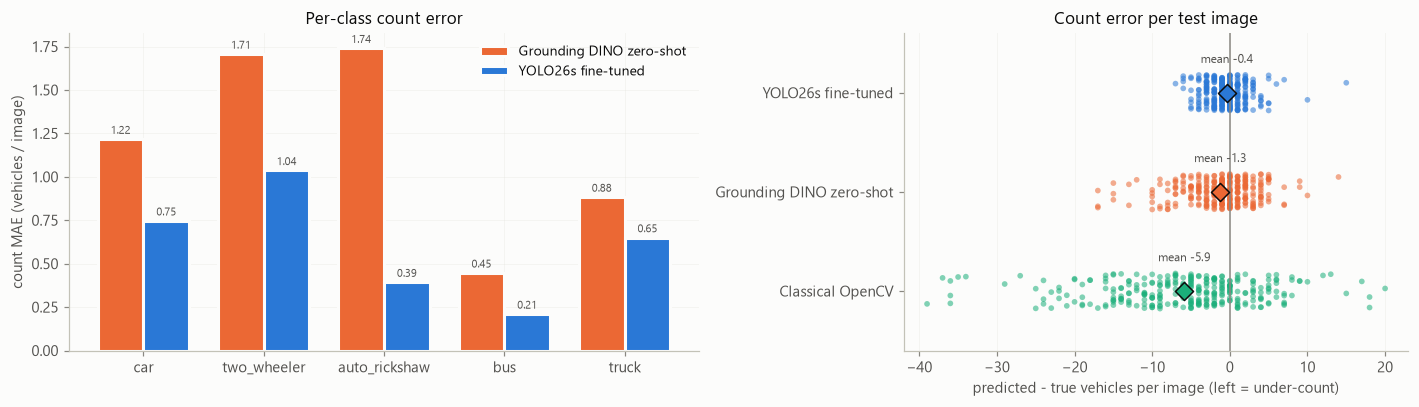

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
# per-class count MAE (classical has no classes)
ax = axes[0]
x = np.arange(len(CLASS_NAMES)); w = 0.38
for k, n in enumerate(["Grounding DINO zero-shot", "YOLO fine-tuned"]):
    vals = [R[n]["count"]["per_class_MAE"][c] for c in CLASS_NAMES]
    bars = ax.bar(x + (k - 0.5) * w, vals, w, color=METHOD_HEX[n], edgecolor="#fcfcfb", linewidth=2,
                  label=disp(n))
    ax.bar_label(bars, fmt="%.2f", fontsize=7, color=INK_2, padding=2)
ax.set_xticks(x, CLASS_NAMES)
ax.set(ylabel="count MAE (vehicles / image)", title=smoke_tag("Per-class count error"))
ax.legend()
# signed count error per image: one jittered row per method, diamond = mean (bias)
ax = axes[1]
jit = np.random.default_rng(SEED)
for row, n in enumerate(names):
    e = np.array([m["total"] for m in PER_IMAGE[n]["meas"]]) - gt_tot
    ax.scatter(e, row + jit.uniform(-0.18, 0.18, len(e)), s=14, color=METHOD_HEX[n], alpha=0.55, edgecolor="none")
    ax.scatter([e.mean()], [row], marker="D", s=70, color=METHOD_HEX[n], edgecolor="#0b0b0b", linewidth=1, zorder=3)
    ax.annotate(f"mean {e.mean():+.1f}", (e.mean(), row + 0.3), ha="center", fontsize=8, color=INK_2)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(names)), [disp(n) for n in names])
ax.set_ylim(-0.6, len(names) - 0.4)
ax.set(xlabel="predicted - true vehicles per image (left = under-count)", title=smoke_tag("Count error per test image"))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "per_class_and_error_hist.png", bbox_inches="tight")
plt.show()

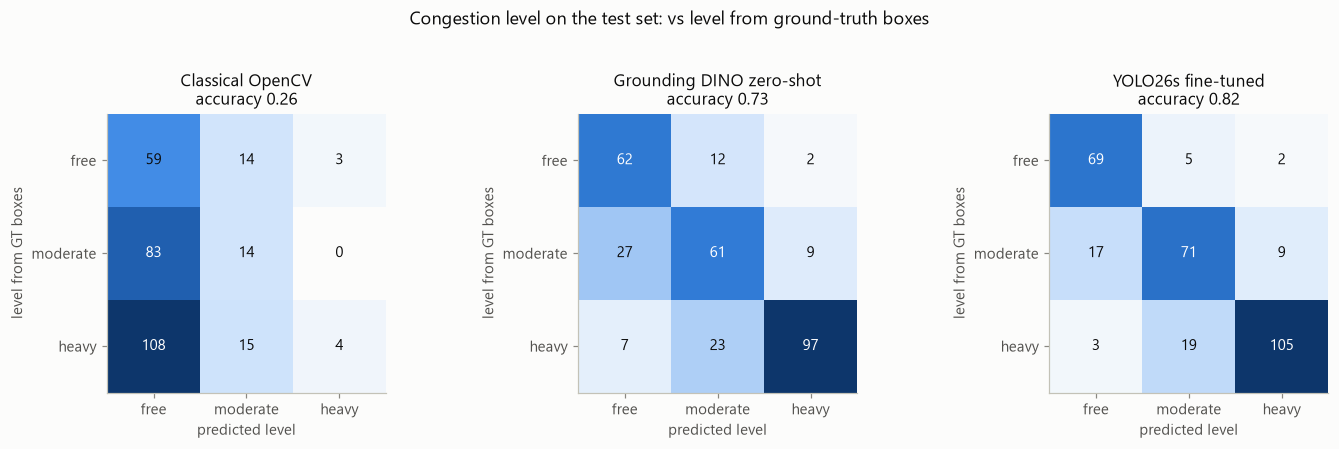

In [15]:
# Congestion level confusion matrices: against manual labels if available, else against the level
# computed from the ground-truth boxes (shows how detection errors change the level).
from sklearn.metrics import confusion_matrix
use_manual = len(manual) > 0
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, n in zip(axes, names):
    if use_manual:
        idx_m = [i for i, p in enumerate(test_paths) if p.name in manual]
        y_true = [manual[test_paths[i].name] for i in idx_m]; y_pred = [PER_IMAGE[n]["levels"][i] for i in idx_m]
    else:
        y_true = [m["congestion_level"] for m in gt_meas]; y_pred = PER_IMAGE[n]["levels"]
    cm = confusion_matrix(y_true, y_pred, labels=LEVELS)
    ax.imshow(cm, cmap=seq_cmap(), vmin=0, vmax=max(cm.max(), 1))
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                    color="#ffffff" if cm[i, j] > 0.55 * max(cm.max(), 1) else "#0b0b0b")
    ax.set_xticks(range(3), LEVELS); ax.set_yticks(range(3), LEVELS)
    ax.set_xlabel("predicted level"); ax.set_ylabel("manual label" if use_manual else "level from GT boxes")
    acc = np.trace(cm) / max(cm.sum(), 1)
    ax.set_title(f"{disp(n)}\naccuracy {acc:.2f}")
    ax.grid(False)
fig.suptitle(smoke_tag("Congestion level on the test set: " + ("vs manual labels" if use_manual else
             "vs level from ground-truth boxes")), y=1.03)
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "congestion_confusion.png", bbox_inches="tight")
plt.show()

## 10. Example outputs
Three test images with low, medium and high ground-truth density: ground truth and the boxes of
each method (at its counting threshold), with the resulting measurement in the title.

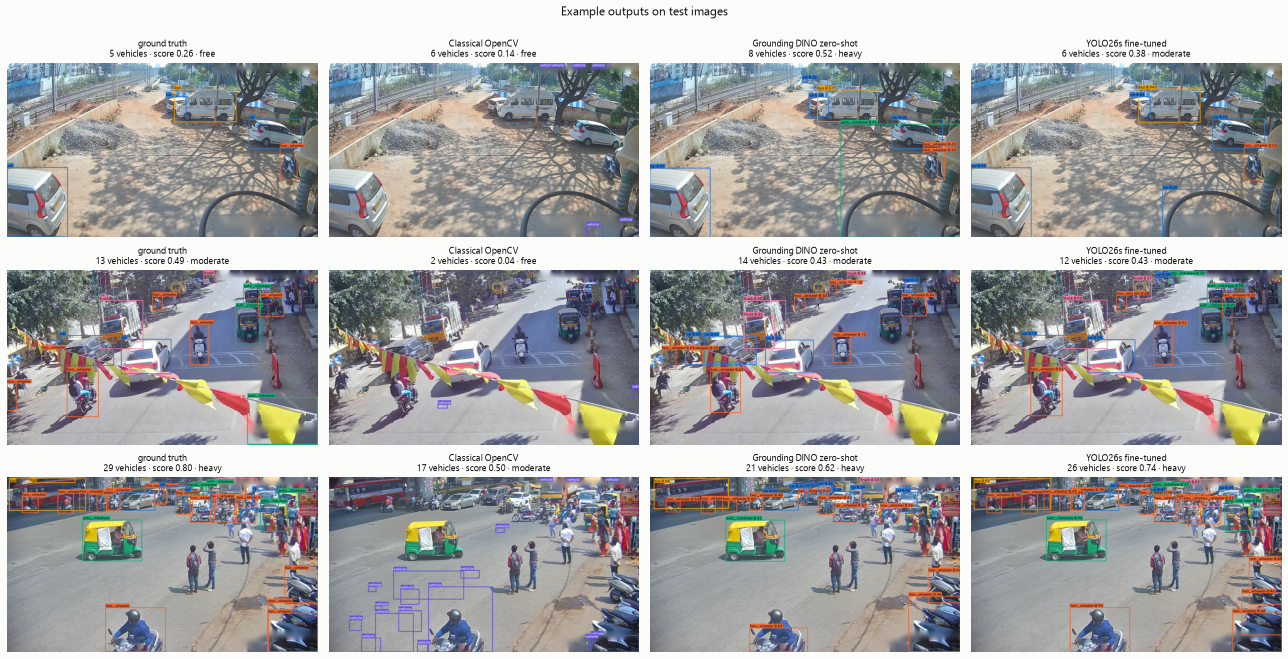

In [16]:
order = np.argsort(gt_tot, kind="stable")
picks = [order[int(q * (len(order) - 1))] for q in np.linspace(0.1, 0.95, N_EXAMPLES)] if len(order) else []
fig, axes = plt.subplots(len(picks), 4, figsize=(18, 3.1 * len(picks)), squeeze=False, dpi=72)
for r_i, i in enumerate(picks):
    img = load_image_rgb(test_paths[i]); g = test_gt[i]
    panels = [("ground truth", draw_detections(img, g["boxes"], g["cls"], roi=g["roi"]), gt_meas[i])]
    for n in ["Classical OpenCV", "Grounding DINO zero-shot", "YOLO fine-tuned"]:
        dets, conf, agn, _, _ = METHODS[n]
        b, s, c = keep_conf([PER_IMAGE[n]["preds_roi"][i]], conf)[0]
        panels.append((disp(n), draw_detections(img, b, c, s if not agn else None, agnostic=agn),
                       PER_IMAGE[n]["meas"][i]))
    for ax, (title, im, m) in zip(axes[r_i], panels):
        ax.imshow(im); ax.axis("off")
        ax.set_title(f"{title}\n{m['total']} vehicles · score {m['congestion_score']:.2f} · {m['congestion_level']}", fontsize=9)
fig.suptitle(smoke_tag("Example outputs on test images"), y=1.0)
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "examples.png", bbox_inches="tight", dpi=110)
plt.show()

## 11. Failure analysis: worst test images for the fine-tuned model
The `WORST_K` test images with the largest absolute count error of the fine-tuned YOLO.
Left: ground truth. Right: predictions; **white boxes tagged "missed"** are ground-truth vehicles with
no prediction (IoU ≥ 0.5, any class) and **violet boxes tagged "FP"** are predictions with no
ground-truth vehicle. The table gives automatic diagnostics to help explain each case.

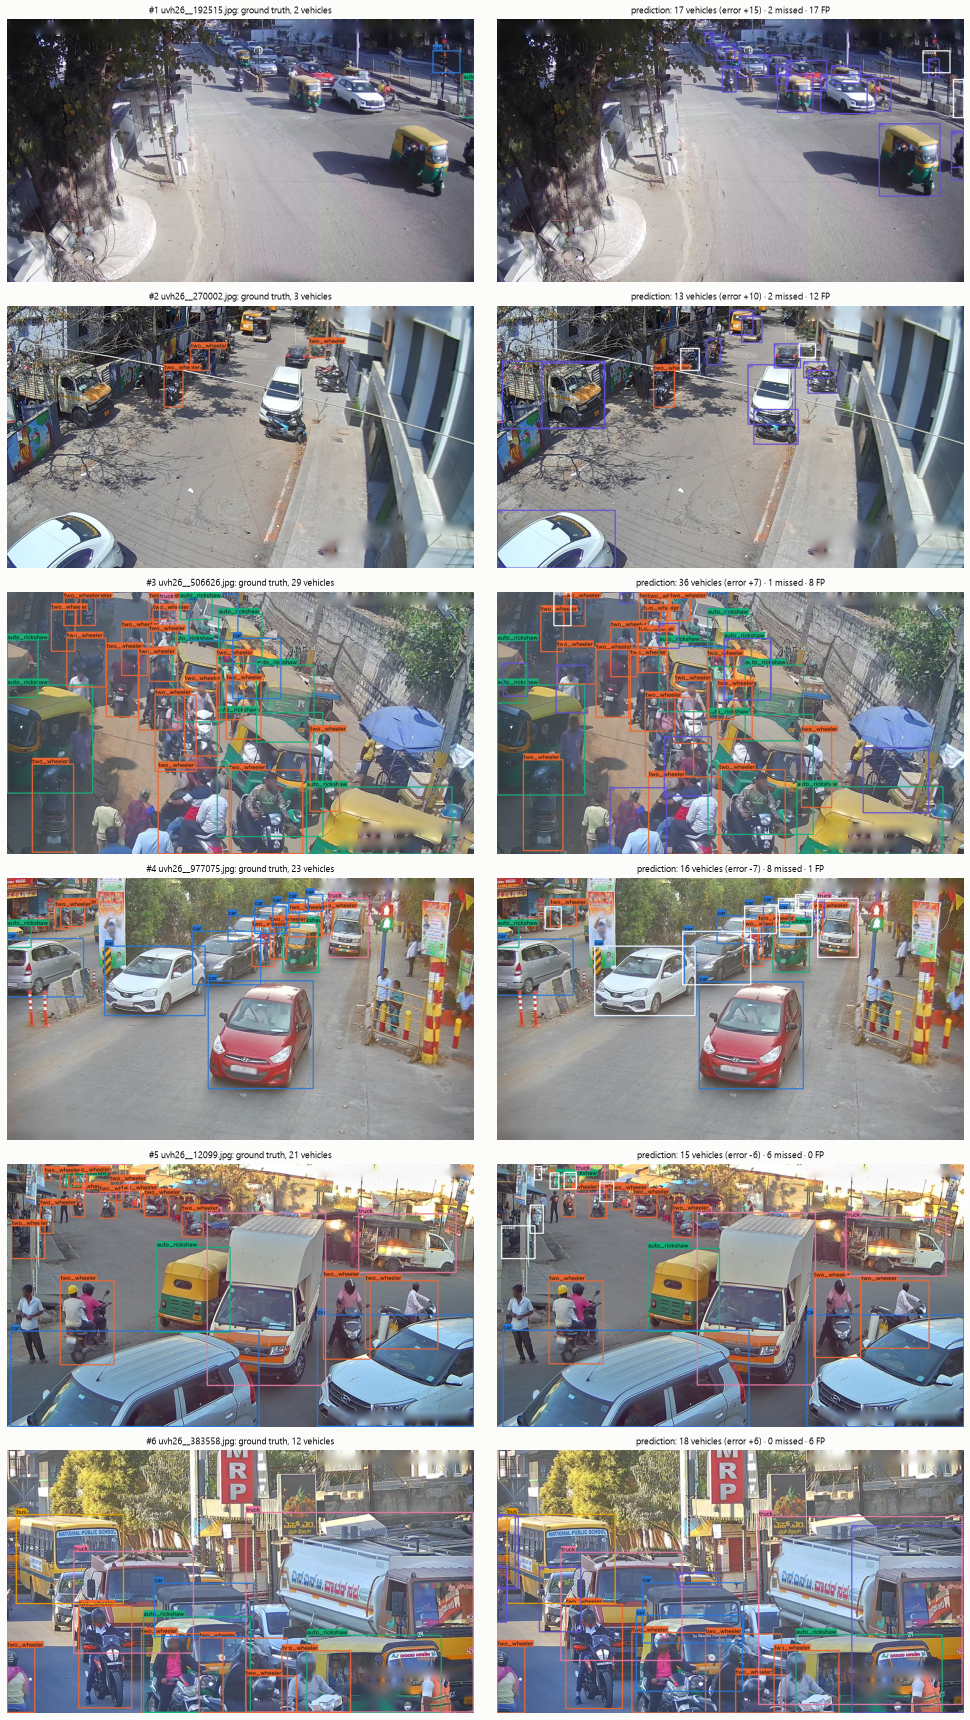

,image,source,GT,pred,error,missed (FN),false pos.,"matched, wrong class",median GT box (% of image),GT boxes < 32x32 px,mean brightness (0-255),GT classes
#,,,,,,,,,,,,
1,uvh26__192515.jpg,UVH-26,2,17,15,2,17,0,0.401,0,122.6,"{'car': 1, 'auto_rickshaw': 1}"
2,uvh26__270002.jpg,UVH-26,3,13,10,2,12,0,0.330,0,134.2,{'two_wheeler': 3}
3,uvh26__506626.jpg,UVH-26,29,36,7,1,8,3,1.769,0,122.1,"{'car': 2, 'two_wheeler': 18, 'auto_rickshaw':..."
4,uvh26__977075.jpg,UVH-26,23,16,-7,8,1,0,0.723,0,142.1,"{'car': 13, 'two_wheeler': 6, 'auto_rickshaw':..."
5,uvh26__12099.jpg,UVH-26,21,15,-6,6,0,0,0.449,0,129.3,"{'car': 2, 'two_wheeler': 14, 'auto_rickshaw':..."
6,uvh26__383558.jpg,UVH-26,12,18,6,0,6,1,5.311,0,130.7,"{'car': 1, 'two_wheeler': 6, 'auto_rickshaw': ..."


In [17]:
smoke_banner()
def agnostic_match(pb, gb, thr=0.5):
    """Greedy class-agnostic matching, highest-IoU pairs first. Returns [(pred index, gt index), ...]."""
    iou = box_iou(pb, gb)
    if iou.size == 0:
        return []
    cand = np.argwhere(iou >= thr)
    cand = cand[np.argsort(-iou[cand[:, 0], cand[:, 1]], kind="stable")]
    pairs, used_p, used_g = [], set(), set()
    for k, j in cand:
        if k not in used_p and j not in used_g:
            pairs.append((int(k), int(j))); used_p.add(k); used_g.add(j)
    return pairs

yolo_err = np.array([m["total"] for m in PER_IMAGE["YOLO fine-tuned"]["meas"]]) - gt_tot
worst = list(np.argsort(-np.abs(yolo_err), kind="stable")[:WORST_K])
diag = []
fig, axes = plt.subplots(len(worst), 2, figsize=(14, 4.0 * len(worst)), squeeze=False, dpi=72)
for r_i, i in enumerate(worst):
    img = load_image_rgb(test_paths[i]); g = test_gt[i]; h, w = img.shape[:2]
    gb, _, gc = test_gt_roi[i]
    pb, ps, pc = keep_conf([PER_IMAGE["YOLO fine-tuned"]["preds_roi"][i]], YOLO_CONF)[0]
    pairs = agnostic_match(pb, gb)
    matched_p, matched_g = {k for k, _ in pairs}, {j for _, j in pairs}
    fp = [k for k in range(len(pb)) if k not in matched_p]
    fn = [j for j in range(len(gb)) if j not in matched_g]
    wrong_cls = sum(int(pc[k] != gc[j]) for k, j in pairs)
    right = draw_detections(img, pb[list(matched_p)], pc[list(matched_p)]) if matched_p else img.copy()
    right = draw_detections(right, pb[fp], pc[fp], color=(98, 80, 214), show_labels=False) if fp else right
    for k in fp:
        x1, y1 = int(pb[k][0]), int(pb[k][1]); cv2.putText(right, "FP", (x1 + 2, y1 + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (98, 80, 214), 2)
    right = draw_detections(right, gb[fn], None, agnostic=True, color=(255, 255, 255), show_labels=False) if fn else right
    for j in fn:
        x1, y1 = int(gb[j][0]), int(gb[j][1]); cv2.putText(right, "missed", (x1 + 2, y1 + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
    axes[r_i, 0].imshow(draw_detections(img, gb, gc)); axes[r_i, 0].axis("off")
    axes[r_i, 0].set_title(f"#{r_i + 1} {test_paths[i].name}: ground truth, {len(gb)} vehicles", fontsize=9)
    axes[r_i, 1].imshow(right); axes[r_i, 1].axis("off")
    axes[r_i, 1].set_title(f"prediction: {len(pb)} vehicles (error {int(yolo_err[i]):+d}) · {len(fn)} missed · {len(fp)} FP", fontsize=9)
    areas = (gb[:, 2] - gb[:, 0]) * (gb[:, 3] - gb[:, 1]) if len(gb) else np.zeros(0)
    diag.append({"#": r_i + 1, "image": test_paths[i].name, "source": source_of(test_paths[i]),
                 "GT": len(gb), "pred": len(pb), "error": int(yolo_err[i]), "missed (FN)": len(fn), "false pos.": len(fp),
                 "matched, wrong class": wrong_cls,
                 "median GT box (% of image)": round(float(np.median(areas) / (h * w) * 100), 3) if len(gb) else None,
                 "GT boxes < 32x32 px": int(((gb[:, 2] - gb[:, 0]) * (gb[:, 3] - gb[:, 1]) < 32 * 32).sum()) if len(gb) else 0,
                 "mean brightness (0-255)": round(float(img.mean()), 1),
                 "GT classes": {CLASS_NAMES[c]: int((gc == c).sum()) for c in np.unique(gc)}})
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "failures.png", bbox_inches="tight", dpi=100)
plt.show()
failures = pd.DataFrame(diag).set_index("#")
display(failures)
failures.to_csv(OUT_DIR / "failure_cases.csv")

### Explanations of the worst cases

_From inspecting the figure above (held-out UVH-26 test cameras)._

1. **`uvh26__192515.jpg`**: Over-count +15, but mostly an **annotation gap**: the ground truth has only 2 boxes while the image clearly shows a queue of autos, cars and two-wheelers. Most 'false positives' are real vehicles. The count error here measures label quality, not the model.
2. **`uvh26__270002.jpg`**: Over-count +10, again **incomplete ground truth**: only 3 two-wheelers are labelled, but the parked truck, the white SUV, the car at the bottom-left and the autos in the background are real vehicles that the model finds.
3. **`uvh26__506626.jpg`**: Over-count +7 in a **very dense, close-up crowd**: riders and pedestrians overlap the two-wheelers, so the model adds duplicate or partial boxes; 3 matched boxes have the wrong class (auto vs two-wheeler under heavy occlusion).
4. **`uvh26__977075.jpg`**: Under-count −7: **small, distant vehicles** at the back of the queue near the top of the frame, and cars hidden behind other cars, are missed or boxed too loosely (IoU < 0.5).
5. **`uvh26__12099.jpg`**: Under-count −6: missed **far-away two-wheelers** at the top-left and vehicles cut by the image border; the large cars in front are detected correctly.
6. **`uvh26__383558.jpg`**: Over-count +6: **large vehicles very close to the camera** (tanker, bus, truck cabin) are partly out of frame and get extra fragment boxes, plus duplicate boxes on two-wheeler riders.

**Common patterns.** (1) Some UVH-26 frames have incomplete labels, which inflates both 'false positives' and the count error. (2) Dense occlusion produces duplicate or mis-classed boxes. (3) Small distant vehicles and objects cut by the frame are missed. Better labels, higher input resolution for far vehicles, and a road ROI that excludes the far background would reduce these errors.

## 12. External test: Wikimedia Commons photos (congestion level)

The box-annotated test set above comes from UVH-26: fixed CCTV cameras, the same kind of view as
training. To see how the system behaves on a **different source**, it is also run on
**Indian road photos from Wikimedia Commons** (openly licensed; author, licence and link for every file in
`data/own_photos/commons_sources.csv`).

* Photos were collected from the Commons categories *Traffic congestion in India* (almost only jams) and
  ordinary street/road categories (*Streets in Bengaluru*, *Streets in Delhi*, ...) for lighter traffic,
  screened by eye (non-road and near-identical shots removed) and checked against train + val
  (no near-duplicates, no shared camera view).
* They are hand-held, ground-level photos, not pole-mounted CCTV: perspective, crop and vehicle scale differ
  from training.
* Each photo has **one manual congestion label** (free / moderate / heavy, judged from the road area
  before any model output was seen), in `data/own_photos/congestion_labels.csv`. There are no ground-truth
  boxes, so this section measures only the final output, the congestion level, not mAP or counts.
* Every method uses exactly the thresholds tuned on the UVH-26 validation set; nothing is re-tuned here.
* Because the labels are unbalanced, accuracy is reported next to **macro-F1** and next to a trivial
  baseline that always predicts the most frequent label.

In [18]:
# External photos: detections -> congestion level, compared with the manual label of each photo
from PIL import Image as PILImage
from sklearn.metrics import f1_score, recall_score

COMMONS_DIR = DATA_DIR / "own_photos"
commons_label_file = COMMONS_DIR / "congestion_labels.csv"
commons_manual = ({} if SMOKE_TEST or not commons_label_file.exists()
                  else pd.read_csv(commons_label_file).set_index("image")["level"].to_dict())
commons_paths = sorted(p for p in (COMMONS_DIR / "images").rglob("*.jpg")
                       if p.relative_to(COMMONS_DIR / "images").as_posix() in commons_manual)
commons_keys = [p.relative_to(COMMONS_DIR / "images").as_posix() for p in commons_paths]
commons_true = [commons_manual[k] for k in commons_keys]
commons_size = [PILImage.open(p).size for p in commons_paths]          # (w, h)
print(f"{len(commons_paths)} external photos with a manual label:",
      pd.Series(commons_true).value_counts().reindex(LEVELS, fill_value=0).to_dict())

C_METHODS, C_LEVELS, C_MEAS, c_rows = {}, {}, {}, []
if commons_paths:
    C_METHODS = {
        "Classical OpenCV": (cached_run("classical_commons", commons_paths, run_classical, CLASSICAL_PARAMS)[0],
                             0.0, True, "classical"),
        "Grounding DINO zero-shot": (cached_run("gdino_commons", commons_paths, run_gdino, gdino_sig)[0],
                                     GDINO_CONF, False, "gdino"),
        "YOLO fine-tuned": (cached_run("yolo_commons", commons_paths, run_yolo, yolo_sig)[0],
                            YOLO_CONF, False, "yolo"),
    }
    majority = pd.Series(commons_true).value_counts().idxmax()
    def level_scores(name, pred):
        rec = recall_score(commons_true, pred, labels=LEVELS, average=None, zero_division=0)
        return {"method": name, "accuracy": float(np.mean([a == b for a, b in zip(pred, commons_true)])),
                "macro-F1": float(f1_score(commons_true, pred, labels=LEVELS, average="macro", zero_division=0)),
                **{f"recall {lv}": float(r) for lv, r in zip(LEVELS, rec)}}
    for n, (dets, conf, agn, tkey) in C_METHODS.items():
        meas = []
        for p, (b, s, c), (w, h) in zip(commons_paths, keep_conf(dets, conf), commons_size):
            roi = get_roi(p, ROIS)
            k = boxes_in_roi(b, w, h, roi)
            meas.append(measure(b[k], c[k], w, h, CFG, roi=roi, class_agnostic=agn, thresholds=THRESHOLDS[tkey]))
        C_MEAS[n] = meas
        C_LEVELS[n] = [m["congestion_level"] for m in meas]
        c_rows.append({**level_scores(disp(n), C_LEVELS[n]),
                       "median vehicles counted": float(np.median([m["total"] for m in meas]))})
    c_rows.append({**level_scores(f"baseline: always '{majority}'", [majority] * len(commons_true)),
                   "median vehicles counted": np.nan})
    COMMONS_RESULTS = pd.DataFrame(c_rows).set_index("method")
    COMMONS_RESULTS.to_csv(OUT_DIR / "commons_results.csv")
    display(COMMONS_RESULTS.round(3))

118 external photos with a manual label: {'free': 33, 'moderate': 23, 'heavy': 62}


  classical_commons: 100/118


classical_commons           : ran on 118 images, 0.030 s/img


  gdino_commons: 100/118


gdino_commons               : ran on 118 images, 0.535 s/img


  yolo_commons: 100/118


yolo_commons                : ran on 118 images, 0.050 s/img


,accuracy,macro-F1,recall free,recall moderate,recall heavy,median vehicles counted
method,,,,,,
Classical OpenCV,0.297,0.198,1.000,0.087,0.000,2.0
Grounding DINO zero-shot,0.636,0.569,0.545,0.304,0.806,12.5
YOLO26s fine-tuned,0.644,0.609,0.636,0.478,0.710,10.0
baseline: always 'heavy',0.525,0.230,0.000,0.000,1.000,NaN


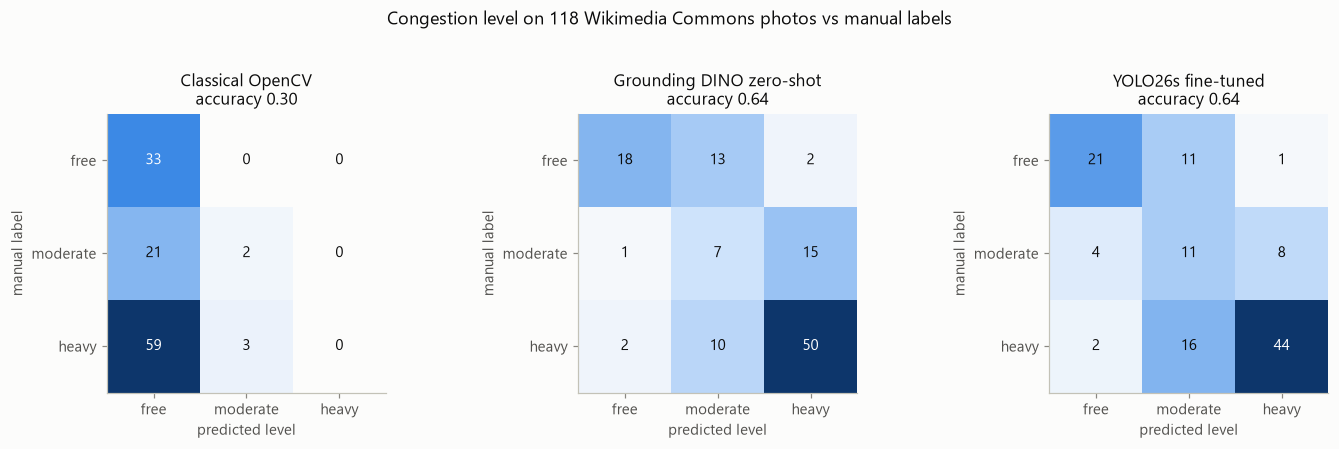

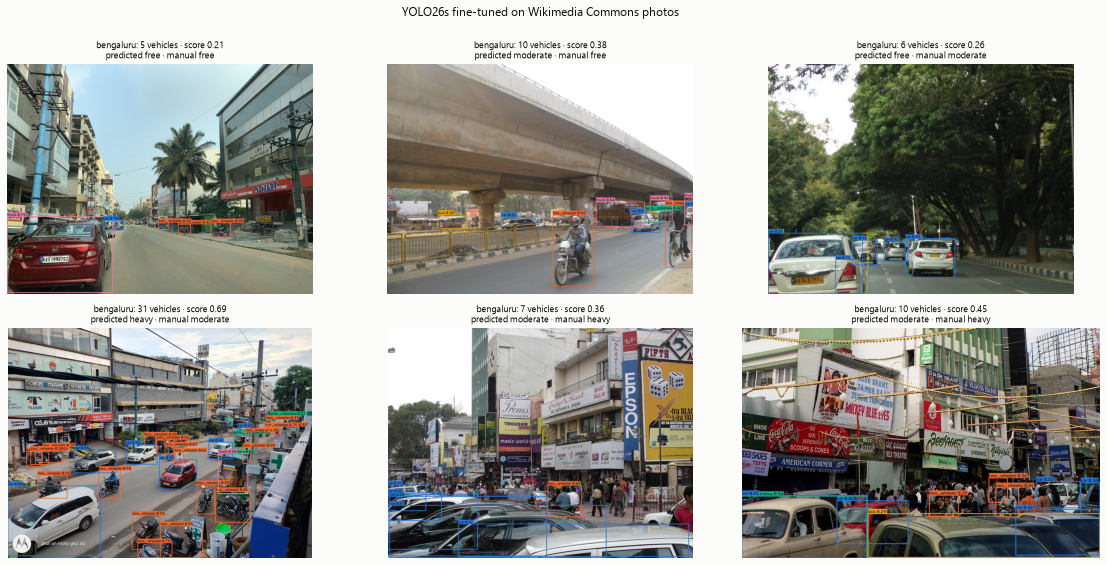

In [19]:
# Confusion matrices on the external photos + example outputs (fine-tuned detector)
if C_METHODS:
    from sklearn.metrics import confusion_matrix
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
    for ax, n in zip(axes, C_METHODS):
        cm = confusion_matrix(commons_true, C_LEVELS[n], labels=LEVELS)
        ax.imshow(cm, cmap=seq_cmap(), vmin=0, vmax=max(cm.max(), 1))
        for i in range(3):
            for j in range(3):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                        color="#ffffff" if cm[i, j] > 0.55 * max(cm.max(), 1) else "#0b0b0b")
        ax.set_xticks(range(3), LEVELS); ax.set_yticks(range(3), LEVELS)
        ax.set_xlabel("predicted level"); ax.set_ylabel("manual label")
        ax.set_title(f"{disp(n)}\naccuracy {np.trace(cm) / max(cm.sum(), 1):.2f}")
        ax.grid(False)
    fig.suptitle(f"Congestion level on {len(commons_paths)} Wikimedia Commons photos vs manual labels", y=1.03)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / "commons_confusion.png", bbox_inches="tight")
    plt.show()

    # two photos per manual level (deterministic), fine-tuned detector output
    picks = [i for lv in LEVELS for i in [j for j, t in enumerate(commons_true) if t == lv][:2]]
    n_col = 3
    fig, axes = plt.subplots((len(picks) + n_col - 1) // n_col, n_col, squeeze=False,
                             figsize=(16, 3.9 * ((len(picks) + n_col - 1) // n_col)), dpi=72)
    dets, conf, _, _ = C_METHODS["YOLO fine-tuned"]
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, picks):
        b, s, c = keep_conf([dets[i]], conf)[0]
        m = C_MEAS["YOLO fine-tuned"][i]
        ax.imshow(draw_detections(load_image_rgb(commons_paths[i]), b, c, s))
        ax.set_title(f"{commons_keys[i].split('/')[0]}: {m['total']} vehicles · score {m['congestion_score']:.2f}\n"
                     f"predicted {m['congestion_level']} · manual {commons_true[i]}", fontsize=9)
    fig.suptitle(f"{disp('YOLO fine-tuned')} on Wikimedia Commons photos", y=1.0)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / "commons_examples.png", bbox_inches="tight", dpi=110)
    plt.show()

### What the external test shows

* **Fine-tuned YOLO is the best method here too**, but the margin is small: accuracy 0.644 and
  macro-F1 0.609, against 0.636 / 0.569 for zero-shot Grounding DINO.
  Both clearly beat the trivial "always heavy" baseline (0.525 accuracy, 0.230 macro-F1).
* **The domain gap is visible.** On UVH-26 test images the fine-tuned model's level agrees with the
  ground-truth-box level on 82 % of images; on these hand-held photos it matches the manual label on
  64 %. Most errors are one level apart. The most common one is a **heavy street scene rated
  moderate** (recall heavy 0.710): in a close-up street photo a jam is a few large cars filling
  the frame, while the road ROI is the whole image (sky and buildings included), so occupancy is diluted and
  the PCU count stays low. CCTV frames, which the thresholds were tuned on, are mostly road.
* **Grounding DINO** detects more vehicles per photo (median 12.5 vs 10)
  and therefore finds heavy scenes more often (recall heavy 0.806), but it pushes many moderate
  scenes to heavy (recall moderate 0.304).
* **The classical pipeline** calls almost everything free (recall free 1.000, recall heavy
  0.000): close vehicles are larger than its maximum blob area and touching vehicles merge,
  so it counts a median of 2 blobs per photo.
* **What would help:** a road polygon per photo (the `roi` argument of `predict`) so occupancy is measured on
  the road only, and level thresholds tuned on a few labelled photos of this kind.

## 13. `predict(image_path)`: the measurement for a new image
Uses the fine-tuned detector from `weights/` with the counting threshold, saturation values and level
thresholds tuned on the validation set above (also saved to `outputs/final/tuned_config.json`).

**To run on a new image:** put the file anywhere inside the project folder (e.g.
`data/own_photos/raw/new.jpg`) and call `predict("data/own_photos/raw/new.jpg")`. Optionally pass
`roi=[[x, y], ...]` (normalised road polygon) to restrict the measurement to the road.

predict('data/test/images/uvh26__216464.jpg')


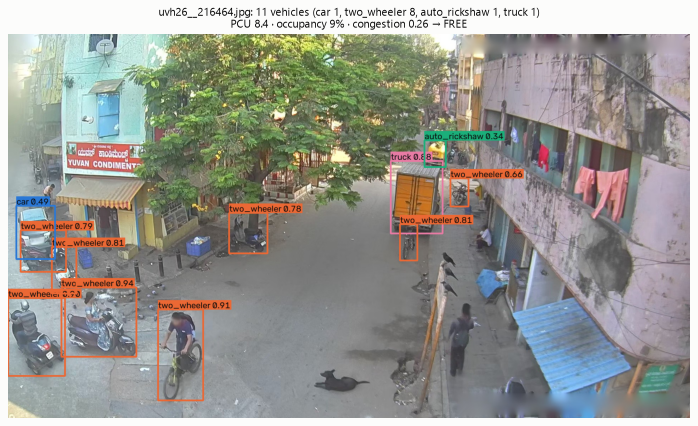

{
  "counts": {
    "car": 1,
    "two_wheeler": 8,
    "auto_rickshaw": 1,
    "bus": 0,
    "truck": 1
  },
  "total": 11,
  "distribution": {
    "car": 0.09090909090909091,
    "two_wheeler": 0.7272727272727273,
    "auto_rickshaw": 0.09090909090909091,
    "bus": 0.0,
    "truck": 0.09090909090909091
  },
  "weighted_count": 8.4,
  "occupancy": 0.0947,
  "congestion_score": 0.2588,
  "congestion_level": "free"
}


In [20]:
def predict(image_path, roi=None, show=True):
    """Measure traffic in one image.

    Returns a dict with: counts per class, total vehicles, vehicle-type distribution, PCU-weighted count,
    road occupancy (0-1), congestion score (0-1) and congestion level (free / moderate / heavy)."""
    img = load_image_rgb(image_path)
    h, w = img.shape[:2]
    roi = roi if roi is not None else get_roi(image_path, ROIS)
    boxes, scores, cls = yolo_detect(yolo, img, conf=YOLO_CONF, imgsz=YOLO_IMGSZ, device=DEVICE)
    result = measure(boxes, cls, w, h, CFG, roi=roi, thresholds=THRESHOLDS["yolo"])
    if show:
        keep = boxes_in_roi(boxes, w, h, roi)
        plt.figure(figsize=(11, 6.5), dpi=80)
        plt.imshow(draw_detections(img, boxes[keep], cls[keep], scores[keep], roi=roi))
        plt.axis("off")
        per = ", ".join(f"{k} {v}" for k, v in result["counts"].items() if v)
        plt.title(f"{Path(image_path).name}: {result['total']} vehicles ({per})\n"
                  f"PCU {result['weighted_count']:.1f} · occupancy {result['occupancy']:.0%} · "
                  f"congestion {result['congestion_score']:.2f} → {result['congestion_level'].upper()}", fontsize=10)
        plt.show()
    return result

demo = next((p for p in test_paths if p.name.startswith("own__")), test_paths[int(order[len(order) // 2])] if len(test_paths) else None)
print(smoke_tag(f"predict({demo.as_posix()!r})"))
print(json.dumps(predict(demo), indent=2))